Genre vs Popularity Function

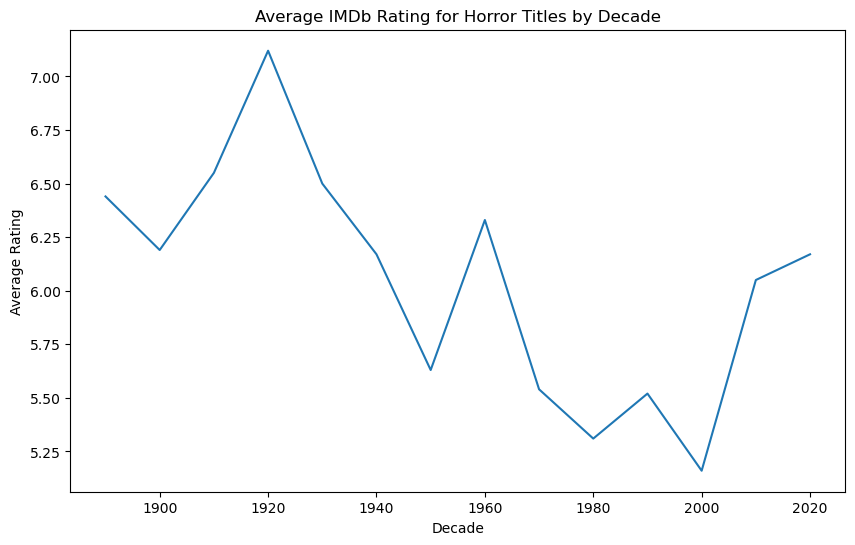

    decade  avg_rating  num_titles
0     1890        6.44          12
1     1900        6.19          10
2     1910        6.55          11
3     1920        7.12          29
4     1930        6.50          61
5     1940        6.17          84
6     1950        5.63         197
7     1960        6.33         468
8     1970        5.54         645
9     1980        5.31         805
10    1990        5.52         761
11    2000        5.16        1934
12    2010        6.05        4429
13    2020        6.17         832


In [47]:
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sqlalchemy as sa
import os

file_name = "IMDb.db"
absolute_path = os.path.abspath(file_name)
conn = sqlite3.connect(absolute_path) 

def genre_rating_by_decade(dbcon, genre, min_votes):
    query = """
    SELECT 
        (t.premiered / 10) * 10 AS decade,         
        ROUND(AVG(r.rating), 2) AS avg_rating,     
        COUNT(*) AS num_titles
    FROM titles t                                  
    JOIN ratings r ON t.title_id = r.title_id
    WHERE t.genres LIKE ?                
        AND r.votes >= ?
        AND t.premiered IS NOT NULL                
    GROUP BY decade
    ORDER BY decade;
    """
    df = pd.read_sql_query(query, con=dbcon, params=(f'%{genre}%', min_votes))

    return df

genre = 'Horror'
df = genre_rating_by_decade(conn, genre, 500)
    
plt.figure(figsize=(10,6))
plt.plot(df['decade'], df['avg_rating'])
plt.title(f'Average IMDb Rating for {genre} Titles by Decade')
plt.xlabel('Decade')
plt.ylabel('Average Rating')
plt.show()

print(df)


In this function, I wanted to take a look at different genres and see what years different genres were most popular or least popular. I wanted the average rating grouped by decade and also wanted the table to return the number of titles in the specified genre for that specific year. I also wanted to minimize outliers, so I decided to add "min_votes" and chose a minimum number of 500 votes for a title to be included. 


In this observation, I wanted to look at what movie genres were the most popular depending on the years they were released. I went for a simple line plot as I wanted the visual to be easily read/accessible as well as also making the function easily changeable. For the genre, I chose horror movies as it is my favorite and I found it interesting that in the 2000s, there was a severe drop in high ratings for this genre. With titles like Saw, Final Destination, and Scream 3 that became instant classics from that era, I expected the rating to be higher. Another thing that surprised me was how high the ratings for movies made in the 1920s were. These high ratings might be because around the 1920's horror movies were pretty new and there were not many to begin with, considering there are only 29 compared to the 2010's had 4429 movies also in this category. This information can be used to track what times different movie genres were popular, especially to track what might be trending next to dictate when new movies should be released to increase release day views and overall ratings.

Genre vs Popularity Function (Popularity Rating per Decade)

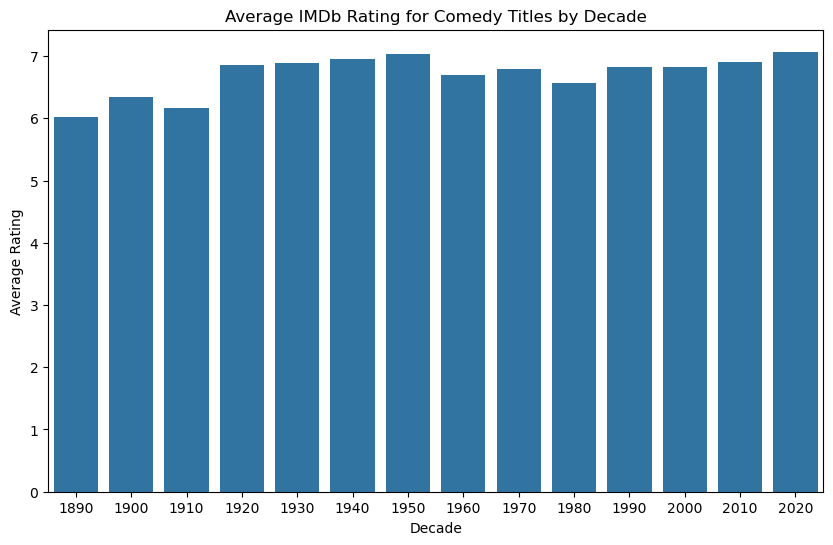

   decade  avg_rating  num_titles
0    1890        6.02          24
1    1900        6.35          46
2    1910        6.17         120
3    1920        6.85         184
4    1930        6.89         610
5    1940        6.95         707
6    1950        7.03         803
7    1960        6.70        1045
8    1970        6.79        1349
9    1980        6.57        2257
10   1990        6.83        4463
11   2000        6.82        9477
12   2010        6.91       15123
13   2020        7.07        2490


In [154]:
genre = 'Comedy'
df = genre_rating_by_decade(conn, genre, 500)

df['decade'] = df['decade'].astype(str)
palette = sns.color_palette("hls", len(df))

plt.figure(figsize=(10,6))
sns.barplot(x='decade',y='avg_rating', data=df)
plt.title(f'Average IMDb Rating for {genre} Titles by Decade')
plt.xlabel('Decade')
plt.ylabel('Average Rating')
plt.show()

print(df)

Actors by Genre Function

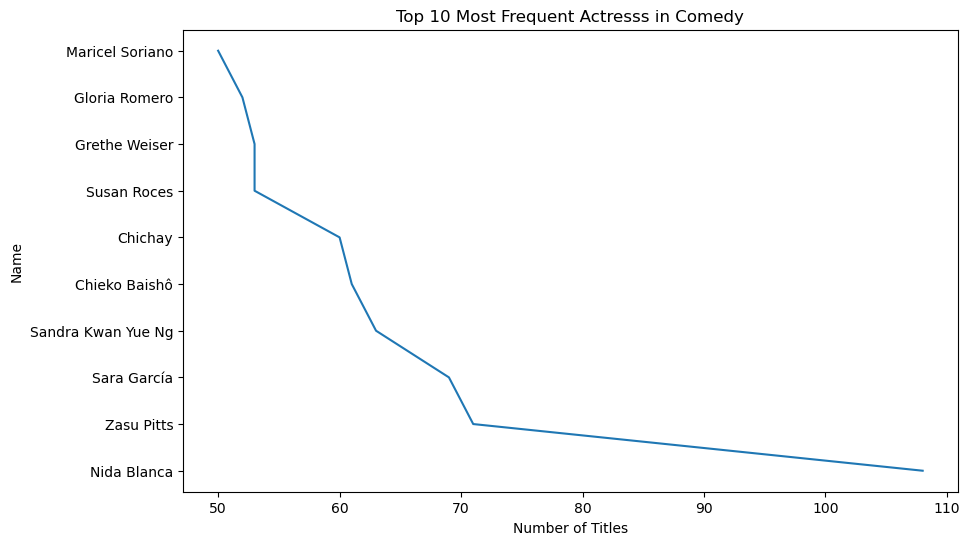

,name,num_titles
0,Nida Blanca,108
1,Zasu Pitts,71
2,Sara García,69
3,Sandra Kwan Yue Ng,63
4,Chieko Baishô,61
5,Chichay,60
6,Susan Roces,53
7,Grethe Weiser,53
8,Gloria Romero,52
9,Maricel Soriano,50


In [132]:
top_n = 10
role = 'actress'

def top_actors_by_genre(conn, genre=genre, role=role, top_n=top_n):
    query = f"""
    SELECT 
        p.name,
        COUNT(DISTINCT t.title_id) AS num_titles
    FROM people p
    JOIN crew c ON p.person_id = c.person_id
    JOIN titles t ON c.title_id = t.title_id
    WHERE c.category = ?
        AND t.genres LIKE ?
        AND t.type = 'movie'
    GROUP BY p.name
    ORDER BY num_titles DESC
    LIMIT ?;
    """
    
    df = pd.read_sql_query(query, conn, params=(role, f'%{genre}%', top_n))
    
    plt.figure(figsize=(10,6))
    plt.plot(df['num_titles'], df['name'])
    plt.title(f'Top {top_n} Most Frequent {role.title()}s in {genre}')
    plt.xlabel('Number of Titles')
    plt.ylabel('Name')
    plt.show()
    
    return df


top_actors_by_genre(conn, genre='Comedy', top_n=10)

For this function, I decided to use an f-string instead of keeping it as plain sql because I found that the data frame that was returned was more neatly organized than my previous function. I specifically wanted to take a look at different roles and their frequencies in different genres. For this visualization, I focused on actresses in the comedy genre and limited my results to give me the top 10. From the people table, I joined person_id with the crew table and as well as joining the title_id tables together from the titles table and crew table. I filtered by the category/job title, genre, and titles, making sure that everything that was returned was a movie, not a TV show. I grouped the number of titles by the person's name as well as set them to be displayed from lowest to highest. 

This visualization shows that Nida Blanca, an actress from the Philippines, starred in the most comedy movies, topping 108 titles. This information can be used from a business perspective when thinking about casting movies when there seems to be a want for new faces on the big screen. New faces are good for new and upcoming film franchises as many times they have not been in enough roles to be typecast and can be seen in different roles easier to the audience.  

I also wanted to add a third visualization of the most frequently seen actors in dramas, an actor named Brahmanandam stars in most dramas. I also wanted to explore using Seaborn visualizations as well as exploring different color palettes. I chose to orient this graph horizontally because in many cases it's easier to visualize, in this case, names, appear in the most titles. 

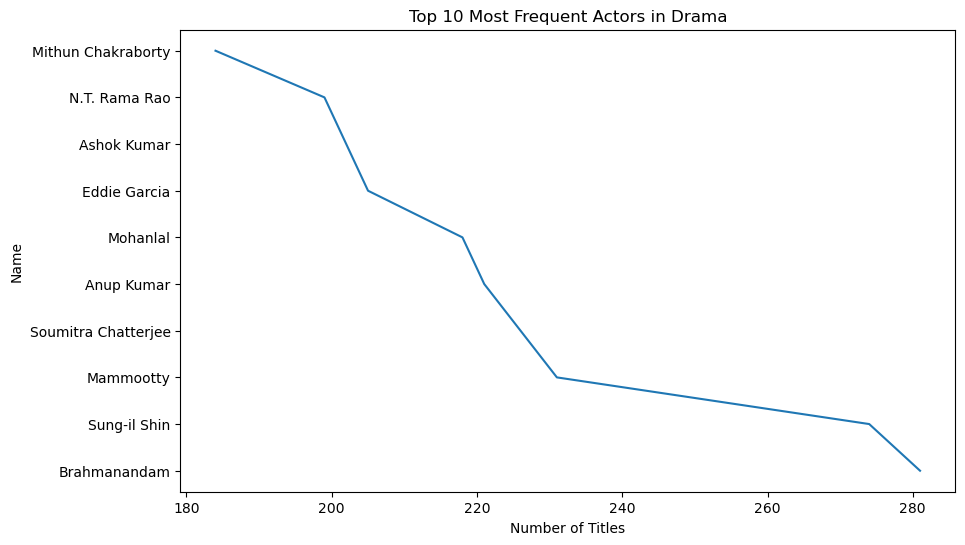

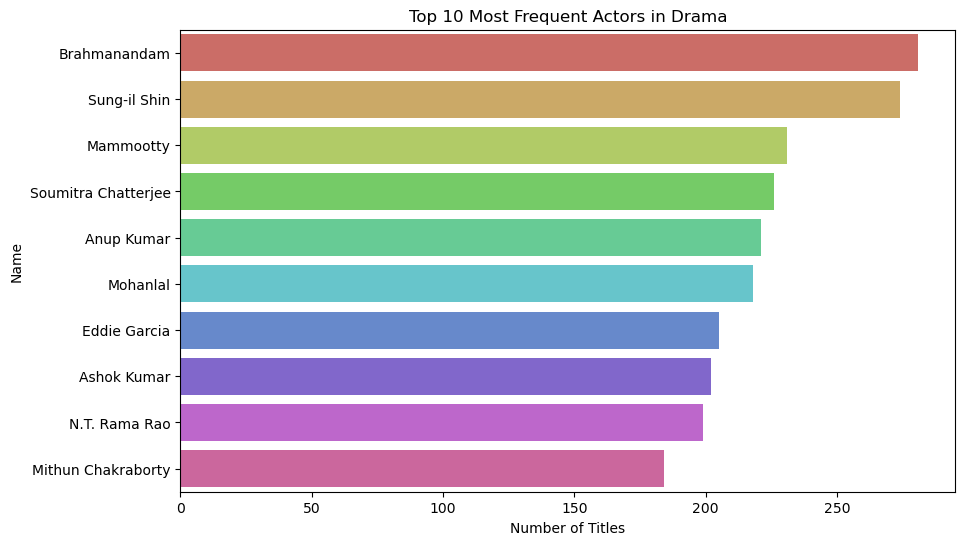

In [152]:
genre="Drama"
role="actor"

df = top_actors_by_genre(conn, genre=genre, role=role, top_n=10)

palette = sns.color_palette("hls", len(df))

plt.figure(figsize=(10, 6))
sns.barplot(x='num_titles', y='name', hue='name', data=df, palette=palette)
plt.title(f'Top {top_n} Most Frequent {role.title()}s in {genre}')
plt.xlabel('Number of Titles')
plt.ylabel('Name')
plt.show()


